# Trabalho prático de NLP — Classificação de notícias REAL e FAKE

**Importação:** Fake.br Corpus, conforme o roteiro da Uninter. Este notebook implementa o fluxo pedido: limpeza com NLTK, normalização de tamanho, TF-IDF com unigramas/bigramas/trigramas, divisão 75/25, regressão logística (`solver="lbfgs"`), avaliação e duas nuvens de palavras.



## 1. Baixar os dados e as máscaras

A base `pre-processed.csv` vem do repositório oficial Fake.br no Github. As máscaras de nuvem são buscadas no repositório de apoio usado no material da disciplina.

In [1]:
from pathlib import Path
import os
import subprocess
import urllib.request

PASTA = Path.cwd()
ARQUIVO_CSV = PASTA / "pre-processed.csv"
URL_CSV = "https://raw.githubusercontent.com/roneysco/Fake.br-Corpus/master/preprocessed/pre-processed.csv"
REPO_AUX = PASTA / "NLP_auxiliar_uninter"

if not ARQUIVO_CSV.exists():
    print("Baixando o corpus Fake.br...")
    urllib.request.urlretrieve(URL_CSV, ARQUIVO_CSV)

if not REPO_AUX.exists():
    print("Baixando arquivos auxiliares e máscaras...")
    subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/N-CPUninter/NLP.git", str(REPO_AUX)],
        check=True
    )

print("CSV disponível:", ARQUIVO_CSV.exists(), "| tamanho (MB):", round(ARQUIVO_CSV.stat().st_size / 1_000_000, 2))
mascaras_encontradas = list(REPO_AUX.rglob("*_mask.png"))
print("Máscaras encontradas:")
for caminho in mascaras_encontradas:
    print(" -", caminho)


CSV disponível: True | tamanho (MB): 20.43
Máscaras encontradas:
 - C:\Users\marco\Downloads\NLP_uninter\NLP_auxiliar_uninter\data\img\cloud_mask.png
 - C:\Users\marco\Downloads\NLP_uninter\NLP_auxiliar_uninter\data\img\mapa_brasil_mask.png
 - C:\Users\marco\Downloads\NLP_uninter\NLP_auxiliar_uninter\data\img\thumbs_down_mask.png
 - C:\Users\marco\Downloads\NLP_uninter\NLP_auxiliar_uninter\data\img\thumbs_up_mask.png


## 2. Instalar/importar bibliotecas e carregar o CSV

Usei o NLTK para tokenização, stopwords em português e stemming. O carregamento tenta identificar o separador e a codificação do arquivo.

In [ ]:
%pip -q install nltk scikit-learn wordcloud pillow pandas matplotlib

import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
from nltk.tokenize import wordpunct_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from wordcloud import WordCloud
from PIL import Image








In [ ]:
nltk.download("stopwords", quiet=True)
nltk.download("rslp", quiet=True)

try:
    df = pd.read_csv(ARQUIVO_CSV, encoding="utf-8", sep=None, engine="python", on_bad_lines="skip")
except UnicodeDecodeError:
    df = pd.read_csv(ARQUIVO_CSV, encoding="latin-1", sep=None, engine="python", on_bad_lines="skip")

In [20]:
print("Dimensões do dataframe:", df.shape)

Dimensões do dataframe: (7200, 3)


In [21]:
print("Colunas:", df.columns.tolist())

Colunas: ['index', 'label', 'preprocessed_news']


In [22]:
display(df.head(3))

,index,label,preprocessed_news
0,0,fake,katia abreu diz vai colocar expulsao moldura n...
1,1,fake,ray peita bolsonaro conservador fake entrevist...
2,2,fake,reinaldo azevedo desmascarado policia federal ...


## 3. Identificar as colunas de texto e de classe

Essa etapa evita assumir nomes de coluna sem verificar o arquivo. O código reconhece nomes comuns da base. Se a identificação automática não for possível, ele interrompe com uma mensagem  para confirir as colunas exibidas na célula anterior.

In [ ]:
def normalizar_nome_coluna(nome):
    nome = unicodedata.normalize("NFKD", str(nome)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "", nome.lower())

colunas_normalizadas = {col: normalizar_nome_coluna(col) for col in df.columns}

# Identifica a coluna de rótulo (classe)
prioridade_rotulo = ["label", "class", "classe", "tipo", "categoria", "target"]
coluna_rotulo = None
for termo in prioridade_rotulo:
    for col, nome_norm in colunas_normalizadas.items():
        if nome_norm == termo or termo in nome_norm:
            coluna_rotulo = col
            break
    if coluna_rotulo is not None:
        break

# Identifica a coluna textual, priorizando nomes que indiquem notícia/texto pré-processado
prioridade_texto = ["preprocessednews", "preprocessed", "news", "noticia", "texto", "text", "content"]
coluna_texto = None
for termo in prioridade_texto:
    candidatos = [col for col, nome_norm in colunas_normalizadas.items()
                  if termo in nome_norm and col != coluna_rotulo]
    if candidatos:
        coluna_texto = candidatos[0]
        break

if coluna_rotulo is None or coluna_texto is None:
    raise ValueError(
        "Não consegui identificar automaticamente as colunas. "
        f"Colunas disponíveis: {df.columns.tolist()}. "
        "Aqui estou definindo manualmente coluna_rotulo e coluna_texto nesta célula."
    )






In [24]:
print("Coluna de rótulo:", coluna_rotulo)

Coluna de rótulo: label


In [25]:
print("Coluna de texto:", coluna_texto)

Coluna de texto: preprocessed_news


In [30]:
df[coluna_rotulo]

0       fake
1       fake
2       fake
3       fake
4       fake
        ... 
7195    true
7196    true
7197    true
7198    true
7199    true
Name: label, Length: 7200, dtype: str

In [31]:
df[coluna_texto]

0       katia abreu diz vai colocar expulsao moldura n...
1       ray peita bolsonaro conservador fake entrevist...
2       reinaldo azevedo desmascarado policia federal ...
3       relatorio assustador bndes mostra dinheiro pub...
4       radialista americano fala sobre pt vendem ilus...
                              ...                        
7195    jornal britanico acao contra lula lava jato se...
7196    temer diz acionou pf cade investigar aumentos ...
7197    obstaculos politicos temer especialistas ouvid...
7198    setembro boa noite aqui estao principais notic...
7199    envolvo politica diz brasileiro preso venezuel...
Name: preprocessed_news, Length: 7200, dtype: str

In [32]:
print("Rótulos originais:", df[coluna_rotulo].value_counts(dropna=False).to_dict())

Rótulos originais: {'fake': 3600, 'true': 3600}


## 4. Limpeza dos textos e padronização dos rótulos



In [33]:
def normalizar_rotulo(valor):
    s = str(valor).strip().lower()
    s_sem_acento = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode("ascii")
    if any(x in s_sem_acento for x in ["fake", "falso", "false", "mentira"]):
        return "FAKE"
    if any(x in s_sem_acento for x in ["true", "real", "verdade", "verdadeiro"]):
        return "REAL"
    # Valores binários não são convertidos silenciosamente, pois o significado de 0/1 pode variar.
    return None

dados = df[[coluna_rotulo, coluna_texto]].copy()
dados = dados.dropna(subset=[coluna_rotulo, coluna_texto])
dados["rotulo"] = dados[coluna_rotulo].map(normalizar_rotulo)
dados = dados.dropna(subset=["rotulo"]).copy()
dados["texto_original"] = dados[coluna_texto].astype(str)
dados = dados[dados["texto_original"].str.strip().ne("")].reset_index(drop=True)

stop_words = set(stopwords.words("portuguese"))
stemmer = RSLPStemmer()

def remover_acentos(texto):
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")

def pre_processar(texto):
    texto = remover_acentos(str(texto)).lower()
    texto = re.sub(r"\d+", " ", texto)  # remove números
    tokens = wordpunct_tokenize(texto)      # tokenização via NLTK
    tokens = [t for t in tokens if t.isalpha()]  # remove pontuação e símbolos
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [stemmer.stem(t) for t in tokens]
    return tokens

dados["tokens"] = dados["texto_original"].apply(pre_processar)
dados = dados[dados["tokens"].map(len) > 0].reset_index(drop=True)


print(" ".join(dados.loc[0, "tokens"][:40]))


Quantidade de notícias após limpeza: 7200
Distribuição das classes:


,quantidade
classe,
FAKE,3600
REAL,3600


Exemplo de texto processado:
kat abr diz vai coloc expulsa mold nao reclam sen kat abr diss expulsa pmdb result aca cupul atual legend segund oportun amanh vou bot mold dour expulsa porqu mao ond vei atest boa condut curricul pesso expuls nao serv


In [34]:
print("Quantidade de notícias após limpeza:", len(dados))

Quantidade de notícias após limpeza: 7200


In [37]:
print("Distribuição das classes:")
display(dados["rotulo"].value_counts().rename_axis("classe").to_frame("quantidade"))

Distribuição das classes:


,quantidade
classe,
FAKE,3600
REAL,3600


In [38]:
print("Exemplo de texto processado:")
print(" ".join(dados.loc[0, "tokens"][:40]))

Exemplo de texto processado:
kat abr diz vai coloc expulsa mold nao reclam sen kat abr diss expulsa pmdb result aca cupul atual legend segund oportun amanh vou bot mold dour expulsa porqu mao ond vei atest boa condut curricul pesso expuls nao serv


## 5. Separar treino e teste e normalizar o comprimento

A divisão é feita antes de ajustar o TF-IDF, evitando que o vocabulário do teste influencie o treinamento. Para reduzir a influência do tamanho dos artigos, o código calcula um limite a partir dos textos de treino e trunca os textos de treino e teste a esse mesmo limite. Isso é uma normalização por limite comum; não equivale a reconstruir os pares originais, que exigiria um identificador de par.

In [ ]:
X_tokens = dados["tokens"].tolist()
y = dados["rotulo"].to_numpy()
indices = np.arange(len(dados))
idx_treino, idx_teste = train_test_split(
    indices, test_size=0.25, random_state=42, stratify=y
)

# Limite de comprimento calculado apenas no treino; percentil 75 evita textos extremos dominarem o modelo.
comprimentos_treino = np.array([len(X_tokens[i]) for i in idx_treino])
LIMITE_PALAVRAS = max(20, int(np.percentile(comprimentos_treino, 75)))

def truncar_tokens(tokens, limite=LIMITE_PALAVRAS):
    return tokens[:limite]

X_treino_texto = [" ".join(truncar_tokens(X_tokens[i])) for i in idx_treino]
X_teste_texto = [" ".join(truncar_tokens(X_tokens[i])) for i in idx_teste]
y_treino = y[idx_treino]
y_teste = y[idx_teste]








In [39]:
print(f"Treino: {len(X_treino_texto)} notícias ({len(X_treino_texto)/len(dados):.0%})")

Treino: 5400 notícias (75%)


In [40]:
print(f"Teste:  {len(X_teste_texto)} notícias ({len(X_teste_texto)/len(dados):.0%})")

Teste:  1800 notícias (25%)


In [41]:
print("Limite comum de palavras por notícia:", LIMITE_PALAVRAS)

Limite comum de palavras por notícia: 518


In [42]:
print("Comprimento médio antes do truncamento (treino):", round(comprimentos_treino.mean(), 1))

Comprimento médio antes do truncamento (treino): 361.6


In [43]:
print("Comprimento médio depois do truncamento (treino):", round(np.mean([len(t.split()) for t in X_treino_texto]), 1))

Comprimento médio depois do truncamento (treino): 270.0


## 6. TF-IDF com unigramas, bigramas e trigramas; treinar regressão logística

`ngram_range=(1, 3)` inclui sequências de uma, duas e três palavras. `fit_transform` é aplicado somente ao treino; no teste usamos apenas `transform`. A regressão logística  utiliza `solver="lbfgs"`.

In [44]:
vetorizador = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=2,
    max_features=100000,
    sublinear_tf=True,
    dtype=np.float32
)
X_treino_tfidf = vetorizador.fit_transform(X_treino_texto)
X_teste_tfidf = vetorizador.transform(X_teste_texto)

modelo = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
modelo.fit(X_treino_tfidf, y_treino)

probabilidades = modelo.predict_proba(X_teste_tfidf)
predicoes = modelo.predict(X_teste_tfidf)
acuracia = accuracy_score(y_teste, predicoes)









In [45]:
print("Formato da matriz TF-IDF de treino:", X_treino_tfidf.shape)

Formato da matriz TF-IDF de treino: (5400, 100000)


In [46]:
print("Tamanho do vocabulário:", len(vetorizador.vocabulary_))

Tamanho do vocabulário: 100000


In [47]:
print(f"Acurácia no conjunto de teste: {acuracia:.4f} ({acuracia:.2%})")

Acurácia no conjunto de teste: 0.9594 (95.94%)


In [48]:
print("\nRelatório de classificação:")
print(classification_report(y_teste, predicoes, digits=4, zero_division=0))


Relatório de classificação:
              precision    recall  f1-score   support

        FAKE     0.9704    0.9478    0.9590       900
        REAL     0.9490    0.9711    0.9599       900

    accuracy                         0.9594      1800
   macro avg     0.9597    0.9594    0.9594      1800
weighted avg     0.9597    0.9594    0.9594      1800



In [49]:
print("Matriz de confusão (ordem das classes:", list(modelo.classes_), "):")

Matriz de confusão (ordem das classes: ['FAKE', 'REAL'] ):


In [50]:
print(confusion_matrix(y_teste, predicoes, labels=modelo.classes_))

[[853  47]
 [ 26 874]]


## 7. Contar unigramas, bigramas e trigramas do vocabulário

A contagem  na célula abaixo informa quantos termos únicos de cada tamanho entraram no vocabulário TF-IDF depois de aplicar `min_df=2` e `max_features=100000`. Esses são os termos disponíveis ao modelo, não o número total de ocorrências no corpus.

In [51]:
nomes_features = vetorizador.get_feature_names_out()
contagem_ngramas = {1: 0, 2: 0, 3: 0}
for termo in nomes_features:
    n = len(termo.split())
    if n in contagem_ngramas:
        contagem_ngramas[n] += 1

resumo_ngramas = pd.DataFrame([
    {"tipo": "Unigramas (1 palavra)", "quantidade_de_termos_unicos": contagem_ngramas[1]},
    {"tipo": "Bigramas (2 palavras)", "quantidade_de_termos_unicos": contagem_ngramas[2]},
    {"tipo": "Trigramas (3 palavras)", "quantidade_de_termos_unicos": contagem_ngramas[3]},
    {"tipo": "Total", "quantidade_de_termos_unicos": sum(contagem_ngramas.values())},
])
display(resumo_ngramas)


,tipo,quantidade_de_termos_unicos
0,Unigramas (1 palavra),12713
1,Bigramas (2 palavras),69385
2,Trigramas (3 palavras),17902
3,Total,100000


## 8. Função para gerar nuvem de palavras

A nuvem usa os pesos TF-IDF médios dos documentos de treinamento de cada classe. Assim, os termos são derivados dos dados usados no modelo, e não de palavras de exemplo. A máscara define apenas o formato da nuvem.

In [52]:
def localizar_mascara(nome_arquivo):
    candidatos = list(REPO_AUX.rglob(nome_arquivo)) if REPO_AUX.exists() else []
    if not candidatos:
        raise FileNotFoundError(
            f"arquivo {nome_arquivo}. Não encontrado "

        )
    return candidatos[0]

def gerar_nuvem_da_classe(rotulo_classe, arquivo_mascara, ru="2071642", max_palavras=180):
    mascara_path = localizar_mascara(arquivo_mascara)
    imagem_mascara = np.array(Image.open(mascara_path).convert("RGB"))

    linhas_classe = np.where(y_treino == rotulo_classe)[0]
    if len(linhas_classe) == 0:
        raise ValueError(f"Não há notícias da classe {rotulo_classe} no treino.")

    # Média dos pesos TF-IDF por termo nos documentos da classe selecionada.
    pesos_medios = np.asarray(X_treino_tfidf[linhas_classe].mean(axis=0)).ravel()
    frequencias = {
        termo: float(peso)
        for termo, peso in zip(nomes_features, pesos_medios)
        if peso > 0 and termo.strip()
    }
    frequencias = dict(sorted(frequencias.items(), key=lambda item: item[1], reverse=True)[:max_palavras])
    if not frequencias:
        raise ValueError(f"Não foi possível obter termos TF-IDF para {rotulo_classe}.")

    cor_contorno = (250, 209, 209) if rotulo_classe == "FAKE" else (219, 240, 223)
    nuvem = WordCloud(
        width=1080,
        height=1080,
        background_color="white",
        mask=imagem_mascara,
        max_words=max_palavras,
        collocations=False,
        contour_width=3,
        contour_color=cor_contorno,
        prefer_horizontal=0.9,
        random_state=42
    ).generate_from_frequencies(frequencias)

    # Cores de apoio do material: vermelho para FAKE e verde para REAL.
    if rotulo_classe == "FAKE":
        nuvem = nuvem.recolor(color_func=lambda *args, **kwargs: f"hsl(0, 80%, {random.randint(30, 60)}%)", random_state=42)
    else:
        nuvem = nuvem.recolor(color_func=lambda *args, **kwargs: f"hsl(130, 40%, {random.randint(30, 60)}%)", random_state=42)

    # Salva a figura completa (incluindo o RU) para inserir no relatório PDF.
    nome_saida = f"nuvem_{rotulo_classe.lower()}_RU_{re.sub(r'[^A-Za-z0-9_-]', '', str(ru))}.png"
    plt.figure(figsize=(10, 9))
    plt.imshow(nuvem, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Nuvem de palavras — {rotulo_classe}", fontsize=16)
    # RU na figura, como solicitado no roteiro da atividade.
    plt.figtext(0.99, 0.015, f"RU: {ru}", ha="right", fontsize=10)
    plt.tight_layout()
    plt.savefig(nome_saida, bbox_inches="tight", dpi=160, facecolor="white")
    plt.show()
    print(f"Classe: {rotulo_classe} | termos na nuvem: {len(frequencias)} | imagem salva: {nome_saida}")
    return frequencias, nome_saida

import random
RU = "2071642"  #  RU antes de gerar nuvens.


## — Notícias verdadeiras (REAL)

 Célula abaixo para gerar a nuvem com a máscara de polegar para cima. A tabela apresenta quantos termos únicos de cada tamanho aparecem no vocabulário e quantos termos foram usados na nuvem REAL.

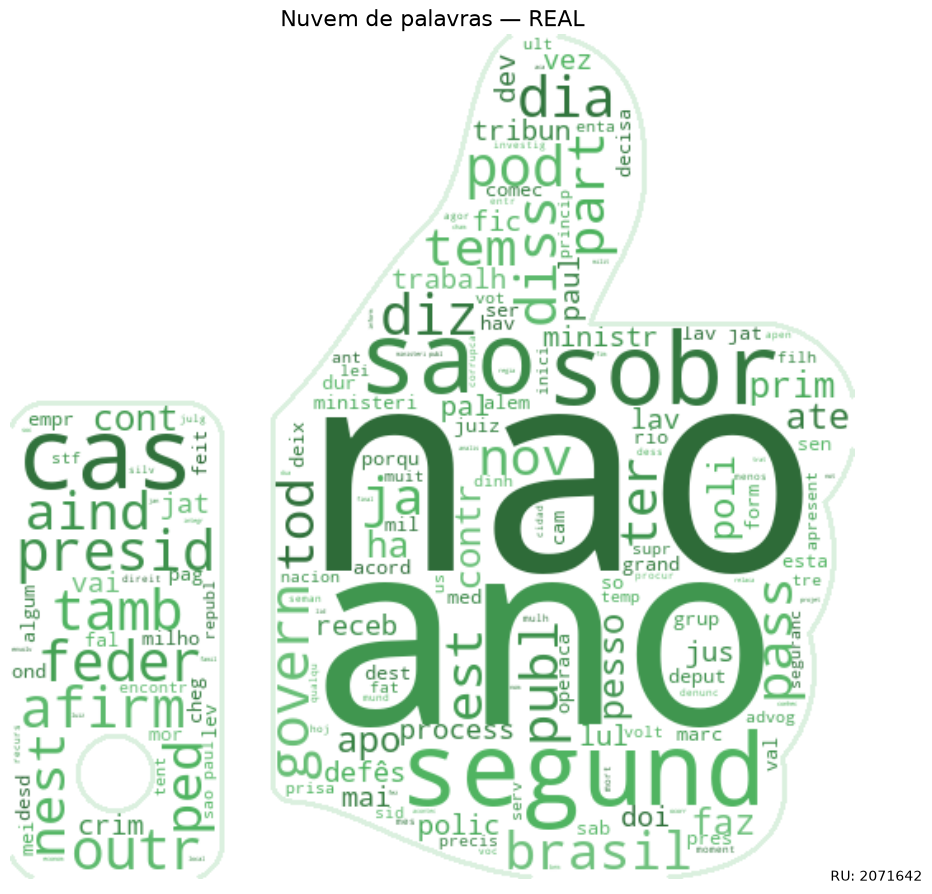

Classe: REAL | termos na nuvem: 180 | imagem salva: nuvem_real_RU_2071642.png
Termos usados na nuvem REAL: 180
Exemplos dos termos com maior peso TF-IDF para REAL:


,termo_ou_ngrama,peso_tfidf_medio
0,nao,0.022285
1,ano,0.018137
2,segund,0.016170
3,cas,0.015405
4,sao,0.015315
5,sobr,0.015196
6,presid,0.015194
7,pod,0.014985
8,tamb,0.014885
9,afirm,0.014865


Contagem do vocabulário por tamanho (compartilhado pelo modelo):


,tipo,quantidade_de_termos_unicos
0,Unigramas (1 palavra),12713
1,Bigramas (2 palavras),69385
2,Trigramas (3 palavras),17902
3,Total,100000


In [53]:
frequencias_REAL, arquivo_nuvem_REAL = gerar_nuvem_da_classe(
    rotulo_classe="REAL",
    arquivo_mascara="thumbs_up_mask.png",
    ru=RU
)

print("Termos usados na nuvem REAL:", len(frequencias_REAL))
print("Exemplos dos termos com maior peso TF-IDF para REAL:")
display(pd.DataFrame(
    sorted(frequencias_REAL.items(), key=lambda item: item[1], reverse=True)[:20],
    columns=["termo_ou_ngrama", "peso_tfidf_medio"]
))
print("Contagem do vocabulário por tamanho (compartilhado pelo modelo):")
display(resumo_ngramas)


## — Notícias falsas (FAKE)

A célula abaixo  gera a nuvem com a máscara de polegar para baixo. Os pesos são calculados somente a partir das notícias FAKE presentes no conjunto de treinamento.

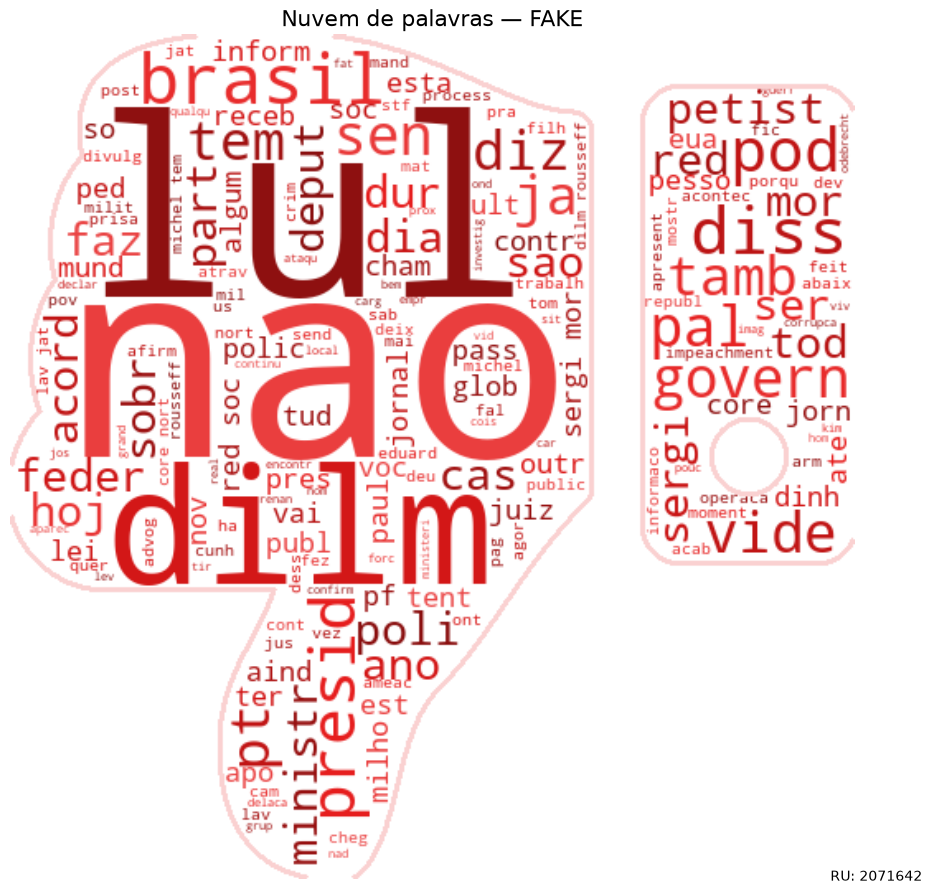

Classe: FAKE | termos na nuvem: 180 | imagem salva: nuvem_fake_RU_2071642.png
Termos usados na nuvem FAKE: 180
Exemplos dos termos com maior peso TF-IDF para FAKE:


,termo_ou_ngrama,peso_tfidf_medio
0,nao,0.020396
1,lul,0.018828
2,dilm,0.014836
3,brasil,0.014506
4,diss,0.013394
5,presid,0.011938
6,pod,0.011598
7,sen,0.009982
8,pal,0.009792
9,vide,0.009677


In [54]:
frequencias_FAKE, arquivo_nuvem_FAKE = gerar_nuvem_da_classe(
    rotulo_classe="FAKE",
    arquivo_mascara="thumbs_down_mask.png",
    ru=RU
)

print("Termos usados na nuvem FAKE:", len(frequencias_FAKE))
print("Exemplos dos termos com maior peso TF-IDF para FAKE:")
display(pd.DataFrame(
    sorted(frequencias_FAKE.items(), key=lambda item: item[1], reverse=True)[:20],
    columns=["termo_ou_ngrama", "peso_tfidf_medio"]
))


## Meu resumo  do relatório

Os valores que aparecerem após executar o notebook:

In [55]:
print("===== RESUMO PARA O RELATÓRIO =====")
print(f"Total de notícias usadas: {len(dados)}")
print(f"Notícias no treino: {len(X_treino_texto)}")
print(f"Notícias no teste: {len(X_teste_texto)}")
print(f"Limite de palavras aplicado por texto: {LIMITE_PALAVRAS}")
print(f"Acurácia: {acuracia:.4f} ({acuracia:.2%})")
print(f"Unigramas únicos no vocabulário: {contagem_ngramas[1]}")
print(f"Bigramas únicos no vocabulário: {contagem_ngramas[2]}")
print(f"Trigramas únicos no vocabulário: {contagem_ngramas[3]}")
print(f"Termos na nuvem REAL: {len(frequencias_REAL)}")
print(f"Termos na nuvem FAKE: {len(frequencias_FAKE)}")
print("Arquivos de imagem:", arquivo_nuvem_REAL, "e", arquivo_nuvem_FAKE)


===== RESUMO PARA O RELATÓRIO =====
Total de notícias usadas: 7200
Notícias no treino: 5400
Notícias no teste: 1800
Limite de palavras aplicado por texto: 518
Acurácia: 0.9594 (95.94%)
Unigramas únicos no vocabulário: 12713
Bigramas únicos no vocabulário: 69385
Trigramas únicos no vocabulário: 17902
Termos na nuvem REAL: 180
Termos na nuvem FAKE: 180
Arquivos de imagem: nuvem_real_RU_2071642.png e nuvem_fake_RU_2071642.png


## Análise do projeto e considerações finais

O desenvolvimento deste projeto me proporcionou a oportunidade de aplicar, na prática, conceitos de Processamento de Linguagem Natural (NLP) e aprendizado de máquina na classificação de notícias verdadeiras e falsas. Durante a realização da atividade, pude compreender melhor como os dados textuais podem ser tratados e transformados em informações que permitem treinar um modelo de classificação.

Um dos principais aprendizados foi perceber que a qualidade do pré-processamento influencia diretamente os resultados de um modelo. A preparação dos textos, a extração de características e a utilização da técnica TF-IDF foram etapas importantes para transformar as notícias em dados que pudessem ser utilizados pelo algoritmo. Também pude compreender melhor a importância de separar os dados de treinamento e teste para avaliar o desempenho do classificador.

A criação das nuvens de palavras contribuiu para a análise visual dos termos presentes nas notícias classificadas como verdadeiras e falsas. Essa etapa também me ajudou a perceber que a frequência de determinadas palavras, isoladamente, não é suficiente para determinar a veracidade de uma informação. Por isso, a análise textual precisa ser combinada com métodos de classificação e avaliações que permitam verificar o desempenho do modelo.

Outro aspecto importante foi compreender que a acurácia deve ser analisada considerando a forma como os dados foram preparados e utilizados no treinamento. Um resultado elevado não significa, necessariamente, que o modelo será igualmente eficiente diante de notícias diferentes daquelas presentes no conjunto de dados utilizado. Essa compreensão reforçou a importância de avaliar os resultados com senso crítico, em vez de considerar apenas o valor obtido.

De maneira geral, este projeto contribuiu para ampliar meus conhecimentos sobre análise de dados textuais, preparação de dados, extração de características e construção de modelos supervisionados. Além disso, permitiu relacionar os conhecimentos teóricos estudados com uma aplicação prática, demonstrando como técnicas de Ciência de Dados podem contribuir para a análise automatizada de informações.

Concluo que a atividade foi importante para minha formação, pois me ajudou a compreender melhor as etapas envolvidas na construção de uma solução baseada em dados, desde a preparação dos textos até a avaliação do modelo. Também reforçou meu entendimento de que o desenvolvimento de soluções de aprendizado de máquina exige não apenas a implementação do código, mas também a interpretação dos resultados, a identificação de limitações e a busca por melhorias contínuas.